In [1]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt

import calendar
from matplotlib.colors import LinearSegmentedColormap

In [2]:
# Load

df = pd.read_csv("data/weather.csv", parse_dates = ["time"], usecols = {"temperature_2m", "time"})

df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2025-01-01", "2026-01-01", inclusive = "left")]

df.head()

,time,temperature_2m
0,2025-01-01 00:00:00-07:00,-9.8
1,2025-01-01 01:00:00-07:00,-9.8
2,2025-01-01 02:00:00-07:00,-10.1
3,2025-01-01 03:00:00-07:00,-11.5
4,2025-01-01 04:00:00-07:00,-11.2


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df[["temperature_2m"]].describe().T)

2025-01-01 00:00:00-07:00 to 2025-12-31 23:00:00-07:00 

Shape: (8760, 2) 

Dtypes:
time              datetime64[us, America/Edmonton]
temperature_2m                             float64
dtype: object 

Any Nulls: False 

Duplicate Rows: False
Duplicate Times: False 

Non-Monotonic Times: False
Unexpected Time Deltas: False 



,count,mean,std,min,25%,50%,75%,max
temperature_2m,8760.0,5.491381,11.953359,-31.6,-1.1,6.8,13.9,31.9


In [4]:
# Clean
# No clean required after inspection.

In [5]:
# Transform

temp_df = (df.assign(month = lambda x: x["time"].dt.month,
                     hour = lambda x: x["time"].dt.hour)
               .groupby(["month", "hour"], as_index = False)
               .agg(avg_temp = ("temperature_2m", "mean")))

# Validate

assert 12 * 24 == len(temp_df)
assert temp_df["avg_temp"].notna().all()

output_df = temp_df.pivot(index = "month", columns = "hour", values = "avg_temp")

output_df

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
month,,,,,,,,,,,,,,,,,,,,,
1,-5.335484,-5.474194,-5.596774,-5.500000,-5.558065,-5.580645,-5.800000,-5.954839,-5.935484,-5.803226,...,-0.596774,-0.570968,-1.241935,-2.667742,-3.590323,-3.970968,-4.348387,-4.654839,-4.770968,-4.935484
2,-13.846429,-14.089286,-14.207143,-14.325000,-14.250000,-14.242857,-14.232143,-14.350000,-14.350000,-13.189286,...,-7.107143,-6.917857,-7.146429,-7.964286,-9.835714,-11.114286,-12.089286,-12.589286,-13.028571,-13.428571
3,-1.387097,-1.870968,-2.453333,-2.583871,-2.729032,-2.983871,-3.074194,-3.258065,-3.077419,-1.735484,...,4.348387,4.932258,5.180645,4.996774,4.012903,2.687097,1.051613,0.141935,-0.451613,-0.970968
4,2.843333,2.256667,1.740000,1.260000,0.986667,0.506667,0.086667,0.150000,1.606667,3.886667,...,10.623333,11.333333,11.820000,11.893333,11.536667,10.643333,8.860000,6.470000,5.070000,3.863333
5,9.383871,8.570968,7.877419,7.170968,6.590323,6.025806,5.664516,6.893548,9.064516,11.570968,...,18.464516,18.980645,19.151613,19.109677,18.603226,17.803226,16.651613,14.351613,12.148387,10.758065
6,11.953333,11.226667,10.543333,9.783333,9.496667,8.976667,8.826667,10.250000,12.103333,14.150000,...,20.170000,20.556667,20.883333,20.963333,20.513333,19.726667,18.736667,16.983333,14.686667,13.250000
7,13.609677,13.041935,12.541935,11.987097,11.919355,11.512903,11.229032,12.048387,13.287097,14.693548,...,19.732258,20.135484,20.935484,21.006452,20.629032,19.783871,18.787097,17.119355,15.393548,14.390323
8,13.890323,13.206452,12.729032,12.132258,11.612903,11.225806,10.787097,10.880645,12.783871,14.987097,...,23.051613,23.632258,23.835484,23.729032,23.235484,22.083871,20.138710,17.345161,15.880645,14.751613
9,11.930000,11.300000,10.743333,10.113333,9.803333,9.166667,8.546667,8.346667,9.006667,11.490000,...,22.270000,23.120000,23.376667,23.326667,22.356667,20.206667,17.153333,15.190000,13.776667,12.746667


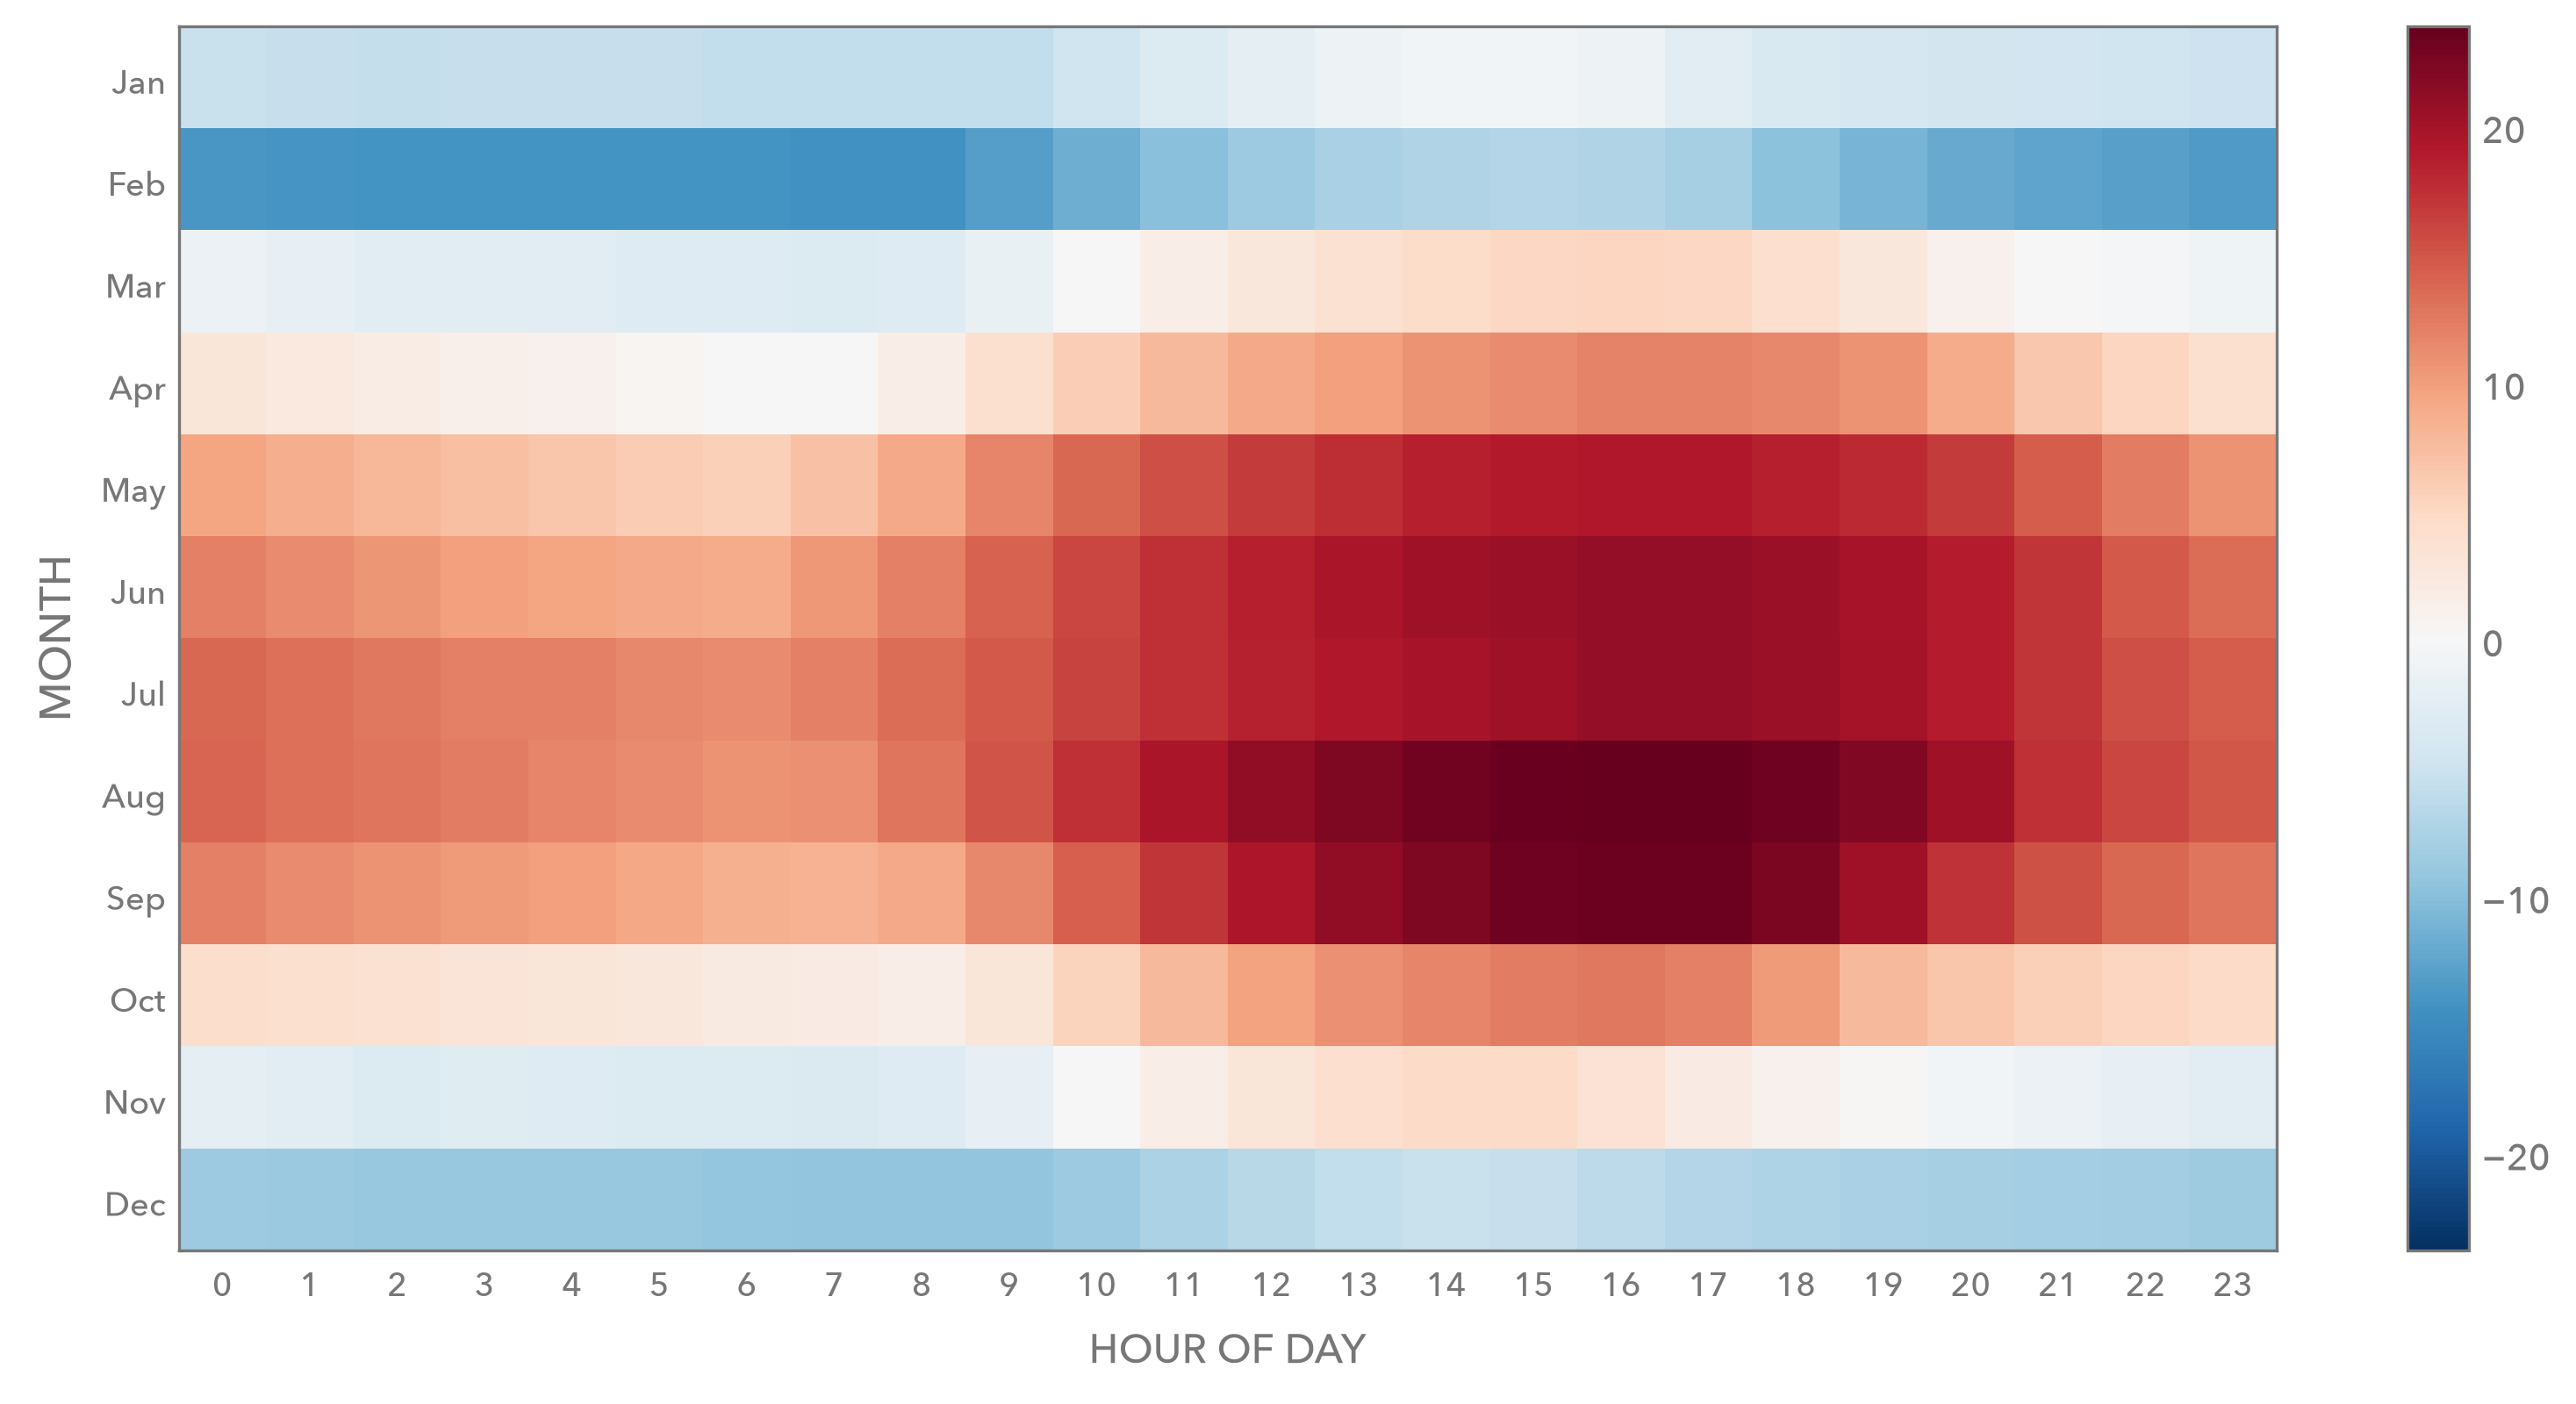

In [52]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (12, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.93,
    top = 0.86,
    bottom = 0.085
)

STRUCTURE = "#777777"
GRID = "#A9A9A9"
BLACK = "#1D1D1D"

# Plot

limit = abs(output_df.to_numpy()).max()

im = ax.imshow(output_df, cmap = "RdBu_r", vmin = -limit, vmax = limit, aspect = "auto")

# Scale & Axes

ax.set_xlabel("HOUR OF DAY", loc = "center", fontsize = 11, fontweight = 500, color = STRUCTURE)
ax.set_ylabel("MONTH", loc = "center", fontsize = 12, fontweight = 500, color = STRUCTURE)

# Ticks

ax.set_xticks(range(24))
ax.set_xticklabels(range(24))
ax.tick_params(axis = "x", labelsize = 9, length = 0, labelcolor = STRUCTURE)

ax.set_yticks(range(12))
ax.set_yticklabels(calendar.month_abbr[1:13])
ax.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "left", "bottom"]].set_color(STRUCTURE)

cbar = fig.colorbar(im, ax = ax)
cbar.outline.set_edgecolor(STRUCTURE)
cbar.ax.tick_params(length = 0, colors = STRUCTURE)

# Output
fig.savefig("outputs/avg_temp_by_month_and_hour_2025.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()